**IMPORTED LIBRARIES**

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [30]:
import pandas as pd
import numpy as np
import tensorflow as tf
import os
import cv2
import random
import gc
import seaborn as sns
import matplotlib.pyplot as plt
from keras.preprocessing.image import load_img
import keras,os
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense, Activation,GlobalMaxPooling2D
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from keras.applications.xception import Xception
from keras.applications.vgg19 import VGG19
from keras.models import Model
from keras import optimizers , layers, applications
from keras import regularizers
from tqdm import tqdm

Adam=tf.keras.optimizers.Adam()

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve

**DATA PREPROCESSING**

In [4]:
train_list_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/train/Autistic')
train_list_non_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/train/Non_Autistic')
test_list_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/test/Autistic')
test_list_non_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/test/Non_Autistic')
valid_list_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/valid/Autistic')
valid_list_non_autistic = os.listdir('/content/drive/MyDrive/AutismDataset1/valid/Non_Autistic')

In [5]:
x_train = np.zeros((len(train_list_autistic)*2, 224,224,3), dtype=np.uint8)
x_val = np.zeros((len(valid_list_autistic)*2, 224,224,3), dtype=np.uint8)
x_test = np.zeros((len(test_list_autistic)*2, 224,224,3), dtype=np.uint8)
y_train = np.zeros((len(train_list_autistic)*2), dtype=np.uint8)
y_val = np.zeros((len(valid_list_autistic)*2), dtype=np.uint8)
y_test = np.zeros((len(test_list_autistic)*2), dtype=np.uint8)

In [6]:
x_train.shape

(2540, 224, 224, 3)

In [7]:
int(len(train_list_non_autistic))

1270

In [8]:
for i in tqdm(range(len(train_list_non_autistic))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/train/Non_Autistic/'+str(train_list_non_autistic[i]), target_size=(224,224), color_mode='rgb')
    x_train[i]=img
for i in tqdm(range(len(train_list_autistic),(2*len(train_list_autistic)))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/train/Autistic/'+str(train_list_autistic[i-int(len(train_list_non_autistic))]), target_size=(224,224), color_mode='rgb')
    x_train[i]=img
    y_train[i]=1

100%|██████████| 1270/1270 [15:34<00:00,  1.36it/s]


In [9]:
for i in tqdm(range(len(valid_list_non_autistic))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/valid/Non_Autistic/'+str(valid_list_non_autistic[i]), target_size=(224,224), color_mode='rgb')
    x_val[i]=img
for i in tqdm(range(len(valid_list_autistic),(2*len(valid_list_autistic)))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/valid/Autistic/'+str(valid_list_autistic[i-int(len(valid_list_non_autistic))]), target_size=(224,224), color_mode='rgb')
    x_val[i]=img
    y_val[i]=1

100%|██████████| 50/50 [00:40<00:00,  1.23it/s]


In [10]:
for i in tqdm(range(len(test_list_non_autistic))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/test/Non_Autistic/'+str(test_list_non_autistic[i]), target_size=(224,224), color_mode='rgb')
    x_test[i]=img
for i in tqdm(range(len(test_list_autistic),(2*len(test_list_autistic)))):
    img =  tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/AutismDataset1/test/Autistic/'+str(test_list_autistic[i-int(len(test_list_non_autistic))]), target_size=(224,224), color_mode='rgb')
    x_test[i]=img
    y_test[i]=1

100%|██████████| 150/150 [02:06<00:00,  1.19it/s]


In [11]:
x_train = x_train/255.0
x_val = x_val/255.0
x_test = x_test/255.0

In [12]:
x_val.shape

(100, 224, 224, 3)

**XCEPTION MODEL**

In [15]:
image_size = 224
input_shape = (image_size, image_size,3)

#Hyperparameters
#epochs = 15
#batch_size = 32

pre_trained_model = Xception(input_shape=input_shape, include_top=False, weights="imagenet")
    
for layer in pre_trained_model.layers:
    layer.trainable = False
    
tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0,
    patience=0,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
)

# Flatten the output layer to 1 dimension
xceptionmodel = keras.models.Sequential()
xceptionmodel.add(pre_trained_model)
xceptionmodel.add(layers.Flatten())
# Add a fully connected layer with 128 hidden units and ReLU activation
xceptionmodel.add(layers.Dense(512, activation='relu'))
# Add a dropout rate of 0.5
#x.add(layers.Dropout(0.5))
# Add a fully connected layer with 64 hidden units and ReLU activation
xceptionmodel.add(layers.Dense(128, activation='relu'))
xceptionmodel.add(layers.Dropout(0.2))
# Add a final sigmoid layer for classification
xceptionmodel.add(layers.Dense(1, activation='sigmoid',kernel_regularizer=regularizers.l2(0.0001)))

xceptionmodel.compile(loss='binary_crossentropy',
             optimizer =  tf.keras.optimizers.Adam(),
              metrics=['accuracy'])

xceptionmodel.summary()




Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 xception (Functional)       (None, 7, 7, 2048)        20861480  
                                                                 
 flatten_1 (Flatten)         (None, 100352)            0         
                                                                 
 dense_3 (Dense)             (None, 512)               51380736  
                                                                 
 dense_4 (Dense)             (None, 128)               65664     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_5 (Dense)             (None, 1)                 129       
                                                                 
Total params: 72,308,009
Trainable params: 51,446,529


In [16]:
#Fit Model
history1 =xceptionmodel.fit(x = x_train,y = y_train, validation_data = (x_val,y_val), epochs = 28, batch_size = 32)

Epoch 1/28
80/80 [==============================] - 16s 153ms/step - loss: 1.6426 - accuracy: 0.6642 - val_loss: 0.5352 - val_accuracy: 0.6900
Epoch 2/28
80/80 [==============================] - 12s 145ms/step - loss: 0.4583 - accuracy: 0.7878 - val_loss: 0.5131 - val_accuracy: 0.7300
Epoch 3/28
80/80 [==============================] - 12s 146ms/step - loss: 0.3611 - accuracy: 0.8346 - val_loss: 0.5694 - val_accuracy: 0.7300
Epoch 4/28
80/80 [==============================] - 12s 147ms/step - loss: 0.2857 - accuracy: 0.8713 - val_loss: 0.6269 - val_accuracy: 0.7200
Epoch 5/28
80/80 [==============================] - 12s 148ms/step - loss: 0.2252 - accuracy: 0.9051 - val_loss: 0.7713 - val_accuracy: 0.7500
Epoch 6/28
80/80 [==============================] - 12s 148ms/step - loss: 0.1738 - accuracy: 0.9280 - val_loss: 0.9461 - val_accuracy: 0.7300
Epoch 7/28
80/80 [==============================] - 12s 150ms/step - loss: 0.1178 - accuracy: 0.9567 - val_loss: 0.7674 - val_accuracy: 0.7700

In [17]:
y_pred1 =xceptionmodel.predict(x_test)

In [18]:
y_pred1 = np.squeeze(y_pred1)

In [19]:
y_pred1 = y_pred1.round()

In [20]:
print(accuracy_score(y_pred1,y_test))

0.86


In [21]:
print(classification_report(y_pred1,y_test))

              precision    recall  f1-score   support

         0.0       0.81      0.90      0.85       136
         1.0       0.91      0.83      0.87       164

    accuracy                           0.86       300
   macro avg       0.86      0.86      0.86       300
weighted avg       0.86      0.86      0.86       300



In [32]:
cn_matrix= confusion_matrix(y_pred1,y_test)
cn_matrix

array([[122,  14],
       [ 28, 136]])

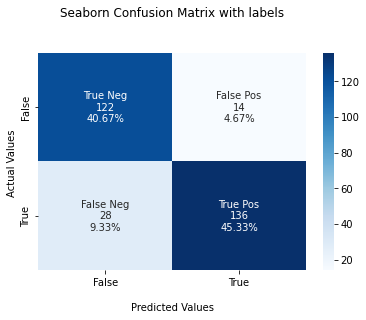

In [35]:
group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                cn_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     cn_matrix.flatten()/np.sum(cn_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(cn_matrix, annot=labels, fmt='', cmap='Blues')

ax.set_title('Seaborn Confusion Matrix with labels\n\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()

In [25]:
print("Average training loss: ", np.average(history1.history['loss']))
print("Average training accuracy: ", np.average(history1.history['accuracy']))
print("Average validation loss: ", np.average(history1.history['val_loss']))
print("Average validation accuracy: ", np.average(history1.history['val_accuracy']))

Average training loss:  0.15233001733681054
Average training accuracy:  0.9501406103372574
Average validation loss:  1.2718733634267534
Average validation accuracy:  0.7539285676819938


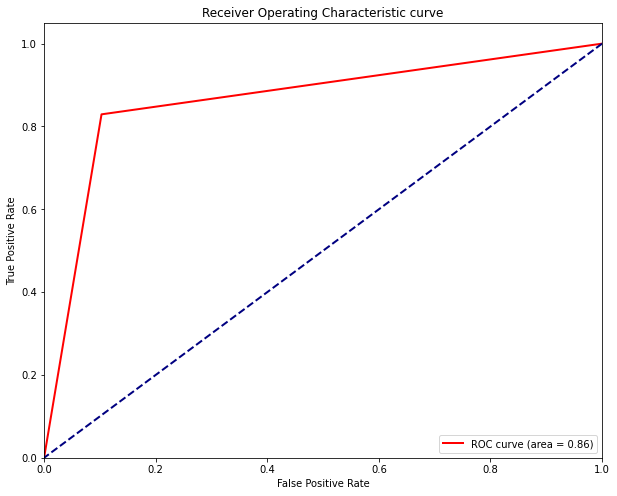

In [28]:
fpr, tpr, _ = roc_curve(y_pred1,y_test)
roc_auc= auc(fpr, tpr)
plt.figure(figsize = (10,8))
plt.plot(fpr, tpr, color = 'red', lw = 2, label = 'ROC curve (area = %0.2f)' % roc_auc)
plt.plot([1,0], [1,0], color = 'navy', lw = 2, linestyle = '--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title("Receiver Operating Characteristic curve")
plt.legend(loc = 'lower right')

**VGG-19 MODEL**

In [36]:
image_size = 224
input_shape = (image_size, image_size,3)

#Hyperparameters
epochs = 30
batch_size = 32

pre_trained_model = VGG19(input_shape=input_shape, include_top=False, weights="imagenet")
    
for layer in pre_trained_model.layers:
    layer.trainable = False

# Flatten the output layer to 1 dimension
vggmodel = keras.models.Sequential()
vggmodel.add(pre_trained_model)
vggmodel.add(layers.Flatten())
# Add a fully connected layer with 128 hidden units and ReLU activation
vggmodel.add(layers.Dense(1024, activation='relu'))
# Add a dropout rate of 0.5
vggmodel.add(layers.Dropout(0.3))
# Add a fully connected layer with 64 hidden units and ReLU activation
vggmodel.add(layers.Dense(512, activation='relu'))
#x.add(layers.Dropout(0.3))
# Add a final sigmoid layer for classification
vggmodel.add(layers.Dense(1, activation='sigmoid',kernel_regularizer=regularizers.l2(0.0001)))

vggmodel.compile(loss='binary_crossentropy',
             optimizer =  tf.keras.optimizers.Adam(),
              metrics=['accuracy'])

vggmodel.summary()


80150528/80134624 [==============================] - 0s 0us/step
Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg19 (Functional)          (None, 7, 7, 512)         20024384  
                                                                 
 flatten_2 (Flatten)         (None, 25088)             0         
                                                                 
 dense_6 (Dense)             (None, 1024)              25691136  
                                                                 
 dropout_2 (Dropout)         (None, 1024)              0         
                                                                 
 dense_7 (Dense)             (None, 512)               524800    
                                                                 
 dense_8 (Dense)             (None, 1)                 513       
                                                       

In [ ]:
#Fit Model
history2 = vggmodel.fit(x = x_train,y = y_train, validation_data = (x_val,y_val), epochs = 28, batch_size = 32)

In [37]:
y_pred1 = vggmodel.predict(x_test)

In [1]:
y_pred1 = np.squeeze(y_pred1)

NameError: ignored

In [ ]:
y_pred1 = y_pred1.round()

In [ ]:
print(accuracy_score(y_pred1,y_test))

In [ ]:
print(classification_report(y_pred1,y_test))

In [ ]:
print(confusion_matrix(y_pred1,y_test))

In [ ]:
group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in
                confusion_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in
                     confusion_matrix.flatten()/np.sum(confusion_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

ax = sns.heatmap(confusion_matrix, annot=labels, fmt='', cmap='Blues')

ax.set_title('Seaborn Confusion Matrix with labels\n\n');
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['False','True'])
ax.yaxis.set_ticklabels(['False','True'])

## Display the visualization of the Confusion Matrix.
plt.show()